In [1]:
!pip install gym gym_bandits

In [2]:
import gym
import gym_bandits

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
import numpy as np
import matplotlib.pyplot as plt
np.bool8 = np.bool_

In [6]:
base_env = gym.make("MultiarmedBandits-v0")
env = base_env.unwrapped
n_arms = env.action_space.n
episodes = 500
print("Number of arms:", n_arms)

Number of arms: 10


/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


/tmp/ipykernel_3808/1607563343.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values[action] += (reward - q_values[action]) / counts[action]



Epsilon-Greedy Results
-----------------------------
Q-values: [-0.86 -0.16 -0.29 -0.96 -0.1  -0.23 -1.44 -0.14 -0.32 -0.12]
Arm selection counts: [  6  55  10   9 351  10   3  20  17  19]
Average reward: -0.1537766420318951


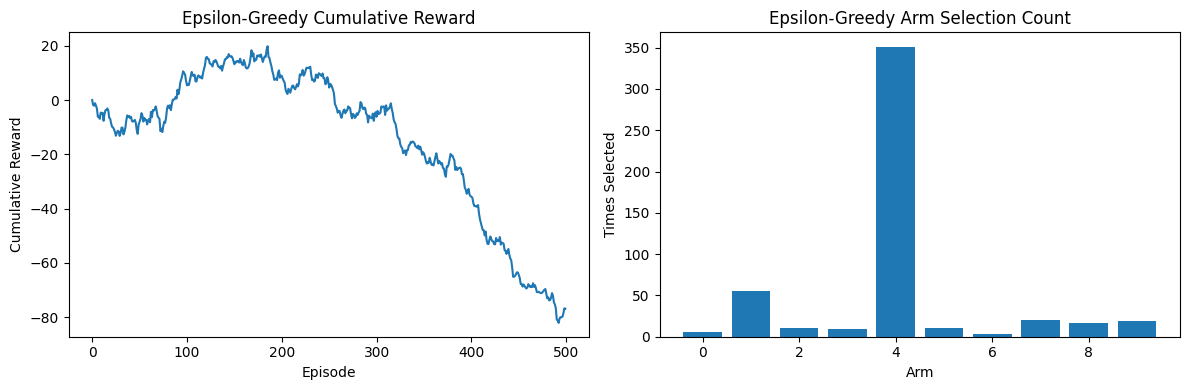


Softmax Results
-----------------------------
Q-values: [-0.34 -0.02  0.13 -2.74  0.1  -0.98  0.01 -0.12 -1.5  -0.08]
Arm selection counts: [ 29  58 111   1 130   4  49  54   2  62]
Average reward: -0.00781375733263545


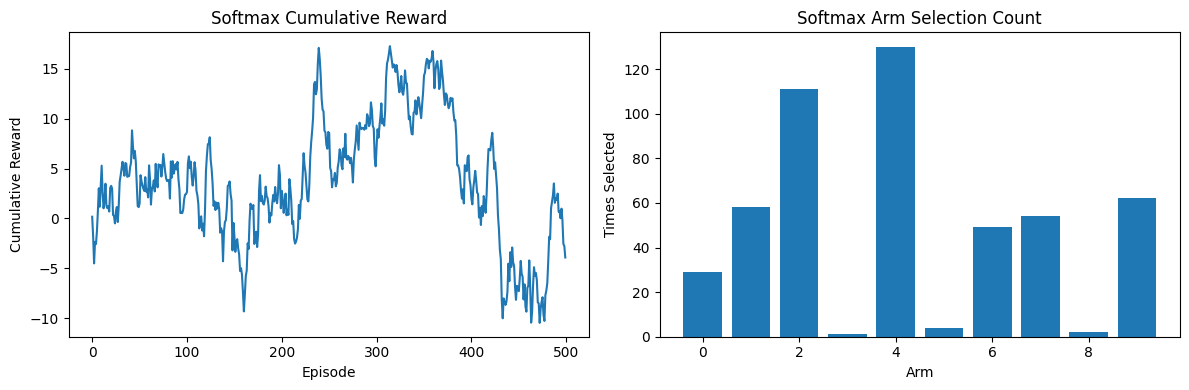

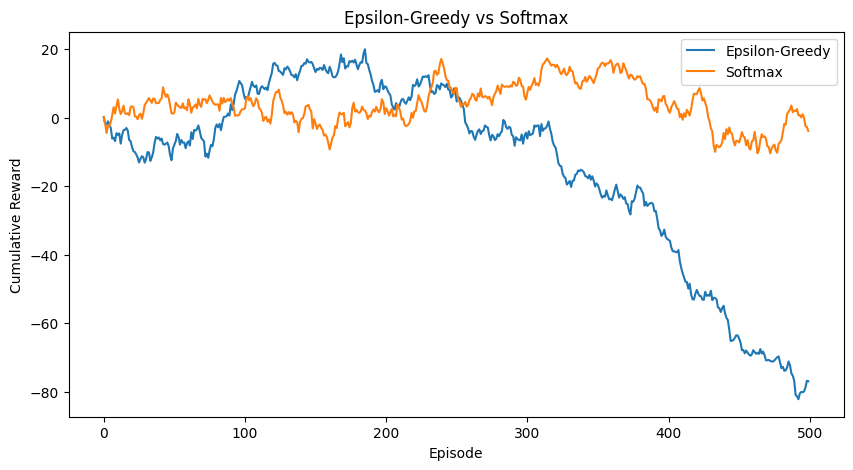

In [7]:
epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
rewards = []
for episode in range(episodes):
    env.reset()
    if np.random.rand() < epsilon:
        action = env.action_space.sample()
    else:
        action = np.argmax(q_values)
    observation, reward, done, info = env.step(action)
    counts[action] += 1
    q_values[action] += (reward - q_values[action]) / counts[action]
    rewards.append(reward)
print("\nEpsilon-Greedy Results")
print("-----------------------------")
print("Q-values:", np.round(q_values, 2))
print("Arm selection counts:", counts.astype(int))
print("Average reward:", np.mean(rewards))
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards))
plt.title("Epsilon-Greedy Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts)
plt.title("Epsilon-Greedy Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()
temperature = 0.5
q_values_softmax = np.zeros(n_arms)
counts_softmax = np.zeros(n_arms)
rewards_softmax = []
for episode in range(episodes):
    env.reset()
    probabilities = np.exp(q_values_softmax / temperature)
    probabilities = probabilities / np.sum(probabilities)
    action = np.random.choice(n_arms, p=probabilities)
    observation, reward, done, info = env.step(action)
    counts_softmax[action] += 1
    q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]
    rewards_softmax.append(reward)
print("\nSoftmax Results")
print("-----------------------------")
print("Q-values:", np.round(q_values_softmax, 2))
print("Arm selection counts:", counts_softmax.astype(int))
print("Average reward:", np.mean(rewards_softmax))
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards_softmax))
plt.title("Softmax Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts_softmax)
plt.title("Softmax Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))
plt.plot(
    np.cumsum(rewards),
    label="Epsilon-Greedy"
)
plt.plot(
    np.cumsum(rewards_softmax),
    label="Softmax"
)
plt.title("Epsilon-Greedy vs Softmax")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.legend()
plt.show()
env.close()